# Logistic Regression

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector,make_column_transformer

# student_dataset_10000_rows

In [3]:
df = pd.read_csv("student_dataset_10000_rows.csv")
df.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed


In [4]:
X, y = df.drop("placement_status",axis=1), df["placement_status"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [5]:
lr = LogisticRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

In [6]:
accuracy_score(y_test,y_pred)

0.9993333333333333

# Kyphosis

In [7]:
df = pd.read_csv("Kyphosis.csv")
df.head()

,Kyphosis,Age,Number,Start
0,absent,71,3,5
1,absent,158,3,14
2,present,128,4,5
3,absent,2,5,1
4,absent,1,4,15


In [8]:
X, y = df.drop("Kyphosis",axis=1), df["Kyphosis"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [9]:
lr = LogisticRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
accuracy_score(y_test,y_pred)

0.88

In [10]:
import sklearn

In [11]:
sklearn.__version__

'1.9.1'

# HR Analytics

In [31]:
df = pd.read_csv("../Day5/HR_comma_sep.csv")
df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14990,0.40,0.57,2,151,3,0,1,0,support,low
14991,0.37,0.48,2,160,3,0,1,0,support,low
14992,0.37,0.53,2,143,3,0,1,0,support,low
14993,0.11,0.96,6,280,4,0,1,0,support,low


In [50]:
# df = pd.read_csv

In [51]:
df.isnull().sum().sum()

0

In [52]:
X, y = df.drop("left",axis=1), df["left"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3,stratify=y)

In [53]:
ohc = OneHotEncoder(sparse_output=False, handle_unknown="ignore",drop="first").set_output(transform="pandas")
ct = make_column_transformer((ohc,make_column_selector(dtype_include=object)),
                             ("passthrough", make_column_selector(dtype_include=['int64','float64'])),
                             verbose_feature_names_out=False)
# ct = ct.set_output(transform="pandas")

In [54]:
lr = LogisticRegression()
pipe = Pipeline([("ct",ct),("lr",lr)])
pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)
accuracy_score(y_test,y_pred)

C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8028450766837075

In [56]:
solvers = ["lbfgs","liblinear","newton-cg","newton-cholesky","sag","saga"]
scores = []
for s in solvers:
    lr = LogisticRegression(solver=s)
    pipe = Pipeline([("ct",ct),("lr",lr)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    scores.append([s,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["K","Score"])
df_scores.sort_values("Score",ascending=False)

C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the 

,K,Score
0,lbfgs,0.802845
2,newton-cg,0.793065
3,newton-cholesky,0.793065
1,liblinear,0.792843
5,saga,0.760613
4,sag,0.753056


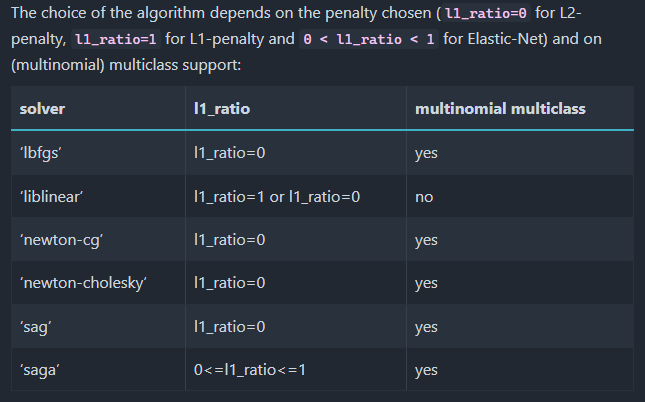

In [39]:
import sklearn
sklearn.__version__

'1.9.1'